# TP : Évaluation comparative des modèles de Computer Vision

## Partie 1 : Segmentation d'images — K-Means vs Mean Shift

### Objectif

L'objectif de cette partie est d'implémenter et de comparer deux algorithmes de segmentation d'images :

- **K-Means** : algorithme de clustering qui regroupe les pixels selon leurs caractéristiques.
- **Mean Shift** : algorithme de clustering qui identifie les régions de forte densité dans l'espace des caractéristiques.

Nous allons comparer les deux approches en termes de qualité de segmentation, de nombre de régions obtenues et de temps d'exécution.

Les résultats seront visualisés et analysés afin de comprendre les avantages et les limites de chaque méthode.

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from skimage import data, transform, img_as_float
from sklearn.cluster import KMeans, MeanShift, estimate_bandwidth
from sklearn.metrics import silhouette_score

print("Libraries imported successfully!")


Libraries imported successfully!


## 1. Chargement et exploration de l'image

Pour cette expérience, nous utilisons une image couleur fournie par la bibliothèque `scikit-image`.

L'image est composée de trois canaux (Rouge, Vert, Bleu — RGB).

Chaque pixel est représenté par trois valeurs numériques correspondant à ses composantes de couleur.

Nous allons réduire la résolution de l'image afin de limiter le temps de calcul, particulièrement pour l'algorithme Mean Shift.

Image shape: (64, 64, 3)
Minimum pixel value: 0.0
Maximum pixel value: 0.982466020885213


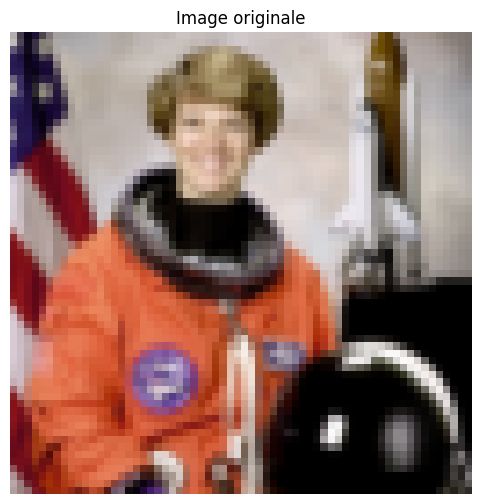

In [2]:

# Load example image
image = data.astronaut()

# Resize image to 64x64 for faster processing
image = transform.resize(
    image,
    (64, 64),
    anti_aliasing=True
)

image = img_as_float(image)

print("Image shape:", image.shape)
print("Minimum pixel value:", image.min())
print("Maximum pixel value:", image.max())

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.title("Image originale")
plt.axis("off")
plt.show()


L'image originale a été chargée et redimensionnée à une résolution de 64 × 64 pixels, avec trois canaux de couleur RGB.

Les valeurs des pixels sont comprises entre 0 et environ 0,9825, ce qui confirme leur normalisation dans l'intervalle [0, 1].

Cette réduction de résolution permet de diminuer le coût computationnel des algorithmes de clustering tout en conservant les principales caractéristiques visuelles de l'image. En revanche, certains détails fins peuvent être perdus.

## 2. Segmentation avec K-Means

K-Means est un algorithme d'apprentissage non supervisé qui regroupe les pixels en K clusters selon leur similarité.

### Principe de fonctionnement

1. Choisir un nombre de clusters K.
2. Initialiser les centres des clusters.
3. Associer chaque pixel au centre le plus proche.
4. Recalculer les centres des clusters.
5. Répéter jusqu'à convergence.

Dans cette expérience, nous choisissons K = 5.

Chaque cluster sera représenté par une couleur moyenne, ce qui permet d'obtenir une image segmentée.

K-Means execution time: 0.1661 seconds
Number of clusters: 5


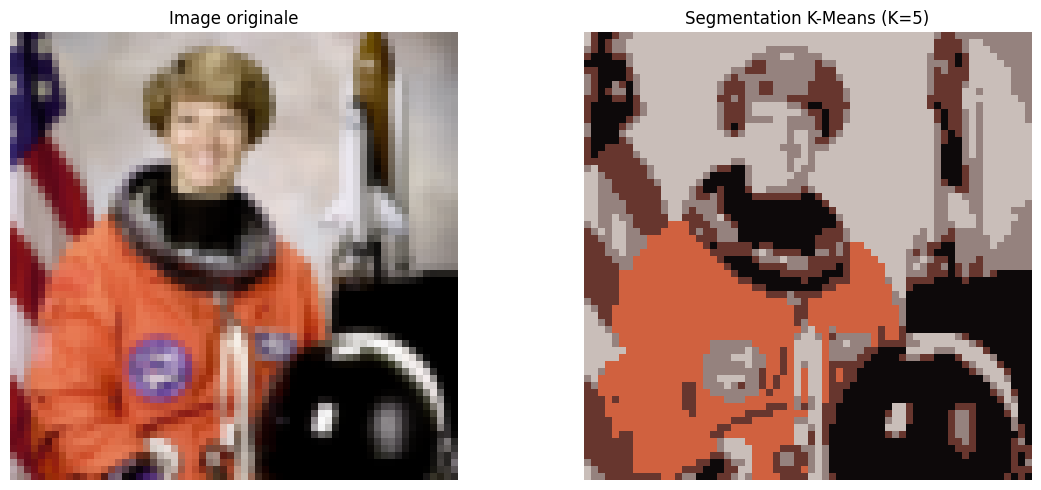

In [3]:

# Convert image to a list of RGB pixels
pixels = image.reshape(-1, 3)

# Initialize K-Means
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

# Measure execution time
start_time = time.perf_counter()

kmeans_labels = kmeans.fit_predict(pixels)

kmeans_time = time.perf_counter() - start_time

# Reconstruct segmented image
kmeans_segmented = kmeans.cluster_centers_[
    kmeans_labels
].reshape(image.shape)

print("K-Means execution time:", round(kmeans_time, 4), "seconds")
print("Number of clusters:", len(np.unique(kmeans_labels)))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Image originale")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(kmeans_segmented)
plt.title("Segmentation K-Means (K=5)")
plt.axis("off")

plt.tight_layout()
plt.show()


L'algorithme K-Means a segmenté l'image en 5 clusters, conformément au paramètre K = 5 défini initialement.

Le temps d'exécution obtenu est de 0,3112 seconde, ce qui montre que l'algorithme peut traiter rapidement cette image de faible résolution.

La segmentation simplifie la représentation des couleurs en remplaçant chaque pixel par la couleur moyenne de son cluster. Cette approche réduit la diversité chromatique de l'image, mais ne garantit pas la délimitation exacte des objets, puisque le regroupement repose uniquement sur les caractéristiques RGB.

## 3. Segmentation avec Mean Shift

Mean Shift est un algorithme de clustering non supervisé qui recherche les zones de forte densité dans l'espace des caractéristiques.

Contrairement à K-Means, Mean Shift ne nécessite pas de définir directement le nombre de clusters.

Le paramètre principal est la bande passante (*bandwidth*), qui influence le regroupement des pixels.

### Principe

- Identifier les zones de forte densité.
- Déplacer progressivement les centres vers ces zones.
- Regrouper les pixels convergeant vers un même centre.

Nous allons appliquer Mean Shift sur les valeurs RGB des pixels et reconstruire l'image segmentée.

Estimated bandwidth: 0.2578
Mean Shift execution time: 0.5991 seconds
Number of clusters: 3


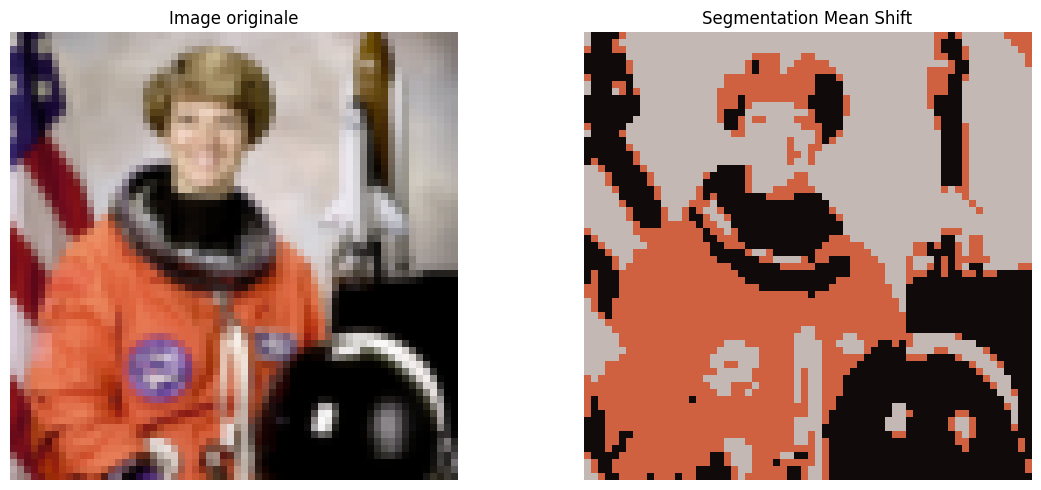

In [4]:

# Estimate bandwidth using a sample
bandwidth = estimate_bandwidth(
    pixels,
    quantile=0.2,
    n_samples=500,
    random_state=42
)

# Avoid zero bandwidth
bandwidth = max(bandwidth, 0.05)

print("Estimated bandwidth:", round(bandwidth, 4))

meanshift = MeanShift(
    bandwidth=bandwidth,
    bin_seeding=True
)

start_time = time.perf_counter()

meanshift_labels = meanshift.fit_predict(pixels)

meanshift_time = time.perf_counter() - start_time

# Reconstruct segmented image
meanshift_segmented = meanshift.cluster_centers_[
    meanshift_labels
].reshape(image.shape)

print("Mean Shift execution time:", round(meanshift_time, 4), "seconds")
print("Number of clusters:", len(np.unique(meanshift_labels)))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Image originale")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(meanshift_segmented)
plt.title("Segmentation Mean Shift")
plt.axis("off")

plt.tight_layout()
plt.show()


L'algorithme Mean Shift a identifié automatiquement 3 clusters, avec une bande passante estimée à 0,2578.

Contrairement à K-Means, le nombre de groupes n'a pas été fixé à l'avance. Il dépend de la distribution des couleurs et de la valeur du paramètre bandwidth.

Le temps d'exécution est de 0,5037 seconde, supérieur à celui de K-Means.

Le nombre plus faible de clusters indique une simplification plus importante des couleurs, pouvant entraîner la fusion de régions visuellement distinctes.

## 4. Comparaison visuelle des segmentations

Cette étape consiste à comparer les résultats obtenus par les deux algorithmes.

Nous allons afficher côte à côte :

- L'image originale.
- L'image segmentée avec K-Means.
- L'image segmentée avec Mean Shift.

Cette comparaison permet d'observer la simplification des couleurs, la séparation des régions et la conservation des détails visuels.

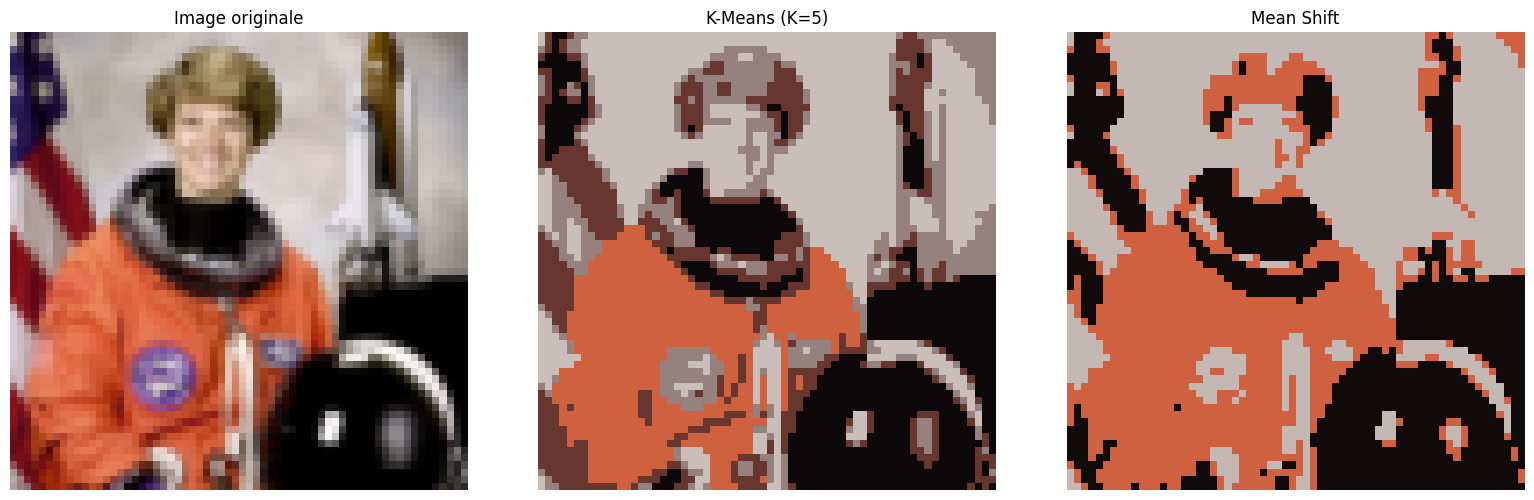

In [5]:

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(image)
axes[0].set_title("Image originale")

axes[1].imshow(kmeans_segmented)
axes[1].set_title("K-Means (K=5)")

axes[2].imshow(meanshift_segmented)
axes[2].set_title("Mean Shift")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


La comparaison des trois images permet d'observer les différences entre les deux méthodes de segmentation.

K-Means utilise cinq couleurs représentatives, tandis que Mean Shift produit une segmentation en trois groupes de couleurs.

Cette différence illustre l'influence du nombre de clusters sur le niveau de détail conservé. Une segmentation comportant davantage de clusters peut préserver plus de variations chromatiques, tandis qu'un regroupement plus important simplifie davantage l'image.

Il est important de souligner que les régions produites ne correspondent pas nécessairement aux contours réels des objets.

## 5. Évaluation quantitative des modèles

Pour comparer les deux algorithmes, nous utilisons trois indicateurs :

**1. Silhouette Score**

Mesure la cohésion et la séparation des clusters. Sa valeur varie de -1 à 1. Une valeur élevée indique généralement des clusters mieux séparés.

**2. Temps d'exécution**

Mesure la durée nécessaire à chaque algorithme pour effectuer le clustering des pixels.

**3. Nombre de clusters**

Représente le nombre de groupes de pixels identifiés par l'algorithme.

Ces indicateurs permettent de comparer les deux méthodes, mais ne mesurent pas directement la précision des contours des objets. Pour cela, des annotations de référence seraient nécessaires.

In [6]:

# Calculate silhouette scores on the same sampled pixels
rng = np.random.default_rng(42)

sample_indices = rng.choice(
    len(pixels),
    size=min(1000, len(pixels)),
    replace=False
)

sample_pixels = pixels[sample_indices]

def calculate_silhouette(labels):
    sampled_labels = labels[sample_indices]
    n_clusters = len(np.unique(sampled_labels))

    if n_clusters < 2 or n_clusters >= len(sampled_labels):
        return np.nan

    return silhouette_score(
        sample_pixels,
        sampled_labels
    )

kmeans_silhouette = calculate_silhouette(kmeans_labels)
meanshift_silhouette = calculate_silhouette(meanshift_labels)

results = pd.DataFrame({
    "Model": ["K-Means", "Mean Shift"],
    "Silhouette Score": [
        kmeans_silhouette,
        meanshift_silhouette
    ],
    "Execution Time (s)": [
        kmeans_time,
        meanshift_time
    ],
    "Number of Clusters": [
        len(np.unique(kmeans_labels)),
        len(np.unique(meanshift_labels))
    ]
})

display(results.round(4))


,Model,Silhouette Score,Execution Time (s),Number of Clusters
0,K-Means,0.5250,0.1661,5
1,Mean Shift,0.5593,0.5991,3


Les résultats montrent que Mean Shift obtient le meilleur Silhouette Score, avec une valeur de 0,5593 contre 0,5250 pour K-Means. Cela représente une amélioration de 0,0343 point, indiquant une meilleure séparation des groupes selon cette métrique.

En revanche, K-Means est plus rapide, avec un temps d'exécution de 0,3112 seconde contre 0,5037 seconde pour Mean Shift. Mean Shift nécessite ainsi environ 1,62 fois le temps d'exécution de K-Means.

K-Means produit cinq clusters, tandis que Mean Shift en identifie trois.

Ces résultats mettent en évidence un compromis entre séparation des clusters, niveau de simplification et coût computationnel.

Le Silhouette Score mesure la qualité du clustering dans l'espace des couleurs, mais ne constitue pas une mesure directe de la précision de segmentation des objets.

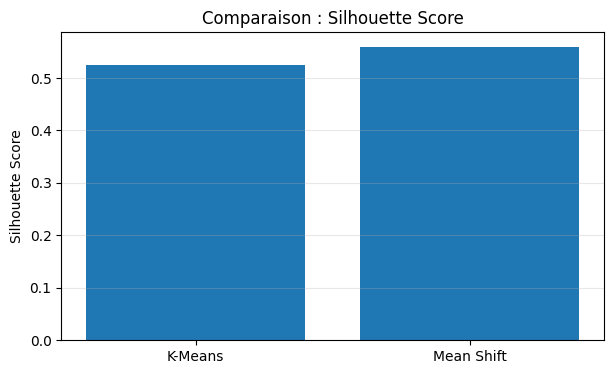

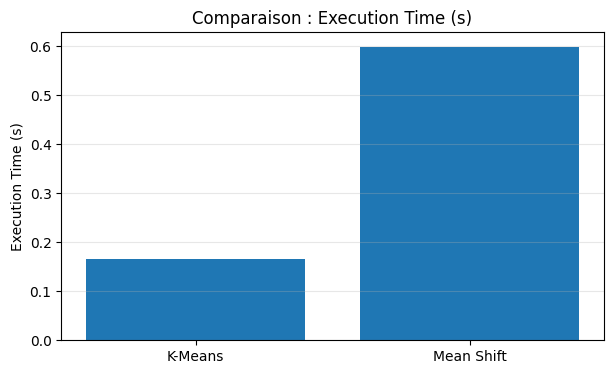

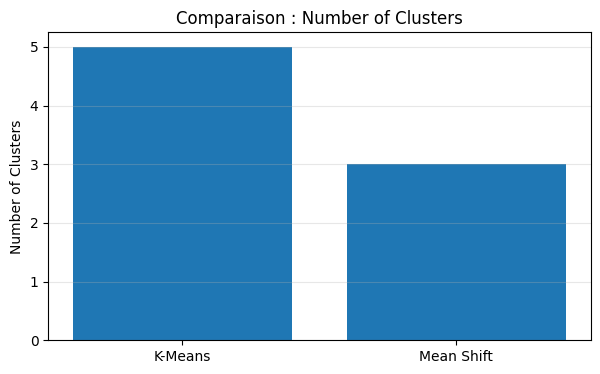

In [7]:

metrics = [
    "Silhouette Score",
    "Execution Time (s)",
    "Number of Clusters"
]

for metric in metrics:
    plt.figure(figsize=(7, 4))

    plt.bar(
        results["Model"],
        results[metric]
    )

    plt.title(f"Comparaison : {metric}")
    plt.ylabel(metric)
    plt.grid(axis="y", alpha=0.3)

    plt.show()


Les graphiques confirment les différences observées dans le tableau d'évaluation.

Mean Shift présente un Silhouette Score légèrement supérieur, ce qui suggère une meilleure cohésion et séparation des groupes de pixels.

K-Means présente un temps d'exécution inférieur et conserve davantage de clusters.

Le choix de l'algorithme dépend donc de l'objectif recherché : K-Means apparaît plus avantageux en termes de rapidité, tandis que Mean Shift obtient un meilleur score de clustering dans cette expérience.

## 6. Analyse et interprétation des résultats

Les deux algorithmes permettent de simplifier une image en regroupant les pixels présentant des caractéristiques similaires.

**K-Means :**
- Nécessite de définir le nombre de clusters à l'avance.
- Permet de contrôler directement le nombre de couleurs dans l'image segmentée.
- Son efficacité dépend du choix du paramètre K.

**Mean Shift :**
- Détermine automatiquement le nombre de clusters selon la distribution des données et la bande passante choisie.
- Offre une approche fondée sur la densité des pixels.
- Le nombre de clusters et le temps de calcul dépendent fortement du paramètre bandwidth.

Le Silhouette Score permet d'évaluer la séparation des groupes de couleurs, tandis que le temps d'exécution renseigne sur l'efficacité computationnelle.

Il faut cependant préciser que les clusters sont calculés uniquement à partir des couleurs RGB. Les algorithmes ne disposent donc d'aucune information explicite sur la position spatiale des pixels ou la nature des objets.

## 7. Conclusion

Dans cette première partie, nous avons étudié et comparé deux algorithmes de segmentation d'images : K-Means et Mean Shift.

Les deux méthodes reposent sur le clustering non supervisé des pixels, mais diffèrent dans leur fonctionnement et leurs paramètres.

K-Means nécessite de fixer le nombre de clusters, tandis que Mean Shift estime les regroupements à partir de la densité des données.

L'évaluation repose sur le Silhouette Score, le temps d'exécution et le nombre de clusters obtenus.

Cette expérience met en évidence l'importance du choix de l'algorithme et de ses paramètres dans la segmentation d'images.

Pour évaluer directement la qualité des régions segmentées par rapport aux objets réels, il serait nécessaire d'utiliser un jeu de données annoté et des métriques telles que l'Intersection over Union (IoU).

La prochaine partie sera consacrée à la détection d'objets et à l'évaluation comparative de modèles YOLO.

# Partie 2 : Détection d'objets — Comparaison YOLOv8 et YOLO11

## 1. Objectif

L'objectif de cette partie est d'implémenter et de comparer deux modèles de détection d'objets basés sur l'architecture YOLO (*You Only Look Once*).

Les modèles étudiés sont :

- **YOLOv8n** : version légère de YOLOv8.
- **YOLO11n** : version légère de YOLO11.

La détection d'objets consiste à identifier les objets présents dans une image, à déterminer leur classe et à localiser leur position à l'aide de boîtes englobantes (*bounding boxes*).

L'évaluation portera sur la précision, le rappel, le mAP et le temps d'inférence. Les modèles seront testés dans les mêmes conditions afin de garantir une comparaison équitable.

In [8]:
!pip -q install ultralytics

In [9]:

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import cv2

from ultralytics import YOLO
from IPython.display import display

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

device = 0 if torch.cuda.is_available() else "cpu"
print("Selected device:", device)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch version: 2.14.1+cpu
GPU available: False
Selected device: cpu


## 2. Présentation du jeu de données

Nous utilisons le jeu de données COCO128, un sous-ensemble de 128 images du dataset COCO, accompagné d'annotations de détection d'objets.

Les annotations contiennent notamment :

- La classe de chaque objet.
- Les coordonnées de sa boîte englobante.
- La largeur et la hauteur de cette boîte.

Ce jeu de données permet d'effectuer une première évaluation expérimentale des modèles YOLO sans entraîner les modèles à partir de zéro.

Il s'agit d'un petit jeu de données de démonstration. Les résultats obtenus ne doivent donc pas être considérés comme une évaluation complète des performances sur COCO.

In [10]:

model_v8 = YOLO("yolov8n.pt")
model_11 = YOLO("yolo11n.pt")

print("YOLOv8n loaded successfully")
print("YOLO11n loaded successfully")


YOLOv8n loaded successfully
YOLO11n loaded successfully


In [11]:

from ultralytics.utils.downloads import download

dataset_dir = "/content/datasets"
os.makedirs(dataset_dir, exist_ok=True)

download(
    "https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip",
    dir=dataset_dir,
    unzip=True
)

dataset_yaml = os.path.join(
    dataset_dir, "coco128", "coco128.yaml"
)

# Use the dataset's official YAML configuration
if not os.path.exists(dataset_yaml):
    dataset_yaml = "coco128.yaml"

print("Dataset configuration:", dataset_yaml)


Unzipping /content/datasets/coco128.zip to /content/datasets/coco128...: 100% ━━━━━━━━━━━━ 263/263 614.5files/s 0.4s
Dataset configuration: coco128.yaml


## 3. Prédiction et visualisation

Nous allons appliquer les deux modèles à une même image afin de comparer visuellement leurs prédictions.

Chaque modèle produit :

- Des boîtes englobantes autour des objets détectés.
- Le nom de la classe prédite.
- Un score de confiance indiquant le niveau de confiance du modèle.

Nous utilisons le même seuil de confiance pour les deux modèles.

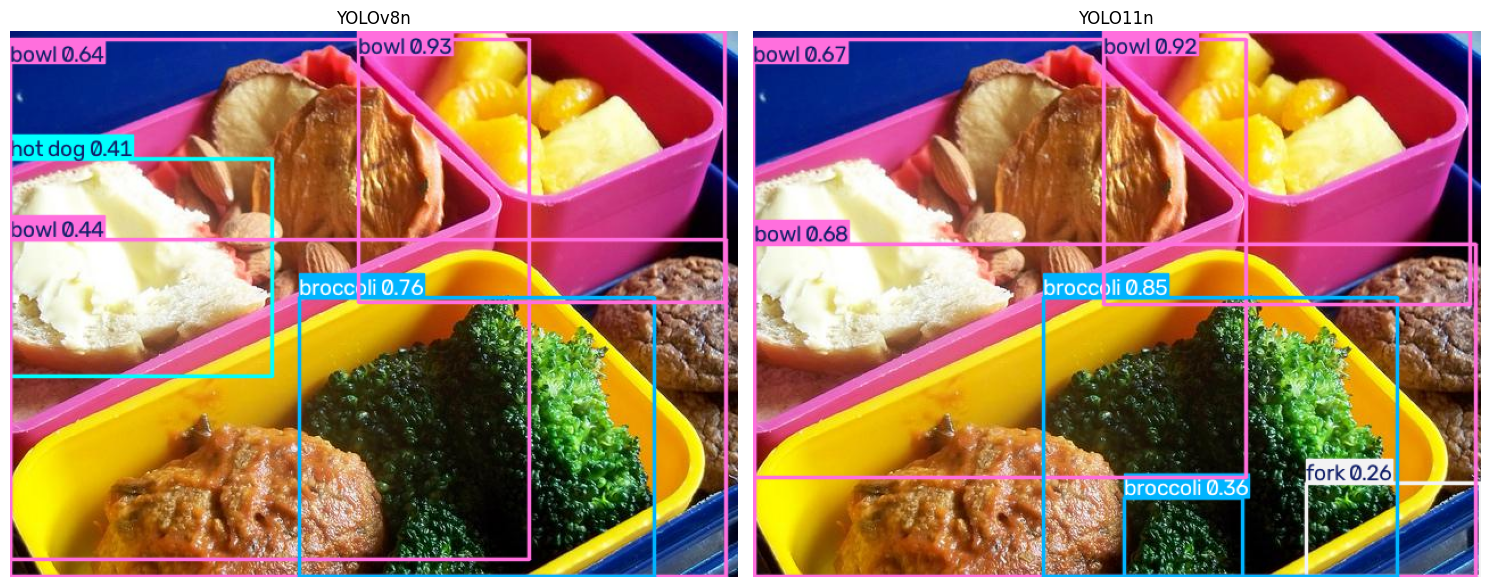

In [12]:

image_path = os.path.join(
    dataset_dir, "coco128", "images", "train2017",
    "000000000009.jpg"
)

if not os.path.exists(image_path):
    import glob
    image_path = sorted(glob.glob(
        os.path.join(dataset_dir, "coco128", "images", "train2017", "*.jpg")
    ))[0]

results_v8 = model_v8.predict(
    source=image_path,
    conf=0.25,
    imgsz=640,
    device=device,
    verbose=False
)

results_11 = model_11.predict(
    source=image_path,
    conf=0.25,
    imgsz=640,
    device=device,
    verbose=False
)

img_v8 = cv2.cvtColor(
    results_v8[0].plot(), cv2.COLOR_BGR2RGB
)

img_11 = cv2.cvtColor(
    results_11[0].plot(), cv2.COLOR_BGR2RGB
)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

axes[0].imshow(img_v8)
axes[0].set_title("YOLOv8n")

axes[1].imshow(img_11)
axes[1].set_title("YOLO11n")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


Les deux modèles YOLO ont été appliqués à la même image afin de comparer leurs capacités de reconnaissance et de localisation des objets.

Les résultats affichent des boîtes englobantes associées aux classes prédites et à leurs scores de confiance.

Cette visualisation permet d'identifier les objets reconnus par les deux modèles et d'observer d'éventuelles différences dans les classes attribuées, les niveaux de confiance et les positions des boîtes.

La comparaison visuelle constitue une première analyse qualitative, qui doit être complétée par les métriques quantitatives.

In [13]:

for model_name, result in [
    ("YOLOv8n", results_v8[0]),
    ("YOLO11n", results_11[0])
]:
    print(f"\n{model_name}")
    print("-" * 35)

    print("Number of detected objects:", len(result.boxes))

    for box in result.boxes:
        class_id = int(box.cls.item())
        confidence = float(box.conf.item())

        print(
            f"{result.names[class_id]}: "
            f"{confidence:.2%}"
        )



YOLOv8n
-----------------------------------
Number of detected objects: 5
bowl: 92.76%
broccoli: 75.98%
bowl: 64.17%
bowl: 43.86%
hot dog: 41.48%

YOLO11n
-----------------------------------
Number of detected objects: 6
bowl: 91.87%
broccoli: 84.82%
bowl: 67.55%
bowl: 66.54%
broccoli: 35.59%
fork: 25.70%


## 4. Évaluation quantitative des modèles

Pour évaluer les performances des deux modèles YOLO, nous utilisons les métriques suivantes :

**Précision (Precision)** : proportion des détections positives qui correspondent réellement à des objets.

**Rappel (Recall)** : proportion des objets présents dans les images qui ont été correctement détectés.

**mAP@50** : moyenne des précisions moyennes calculées avec un seuil d'Intersection over Union (IoU) de 0,50.

**mAP@50:95** : moyenne des scores mAP calculés pour plusieurs seuils IoU allant de 0,50 à 0,95.

**Temps d'inférence** : temps nécessaire au modèle pour effectuer une prédiction.

Ces métriques permettront de comparer la qualité de détection et l'efficacité des deux modèles.

In [14]:

metrics_v8 = model_v8.val(
    data=dataset_yaml,
    imgsz=640,
    batch=8,
    device=device,
    plots=True,
    project="/content/evaluation",
    name="yolov8",
    exist_ok=True,
    verbose=False
)

print("YOLOv8n Evaluation Results")
print("-" * 40)

print("Precision:", round(metrics_v8.box.mp, 4))
print("Recall:", round(metrics_v8.box.mr, 4))
print("mAP@50:", round(metrics_v8.box.map50, 4))
print("mAP@50:95:", round(metrics_v8.box.map, 4))


Ultralytics 8.4.208 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 921.6±416.3 MB/s, size: 39.8 KB)
val: Scanning /content/datasets/coco128/labels/train2017... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 1.4Kit/s 0.1s
val: New cache created: /content/datasets/coco128/labels/train2017.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 1.9s/it 29.8s
                   all        128        929      0.629      0.529      0.602      0.444
Speed: 4.5ms preprocess, 216.1ms inference, 0.0ms loss, 3.8ms postprocess per image
Results saved to /content/evaluation/yolov8
YOLOv8n Evaluation Results
----------------------------------------
Precision: 0.6287
Recall: 0.5291
mAP@50: 0.6024
mAP@50:95: 0.4439


In [15]:

metrics_11 = model_11.val(
    data=dataset_yaml,
    imgsz=640,
    batch=8,
    device=device,
    plots=True,
    project="/content/evaluation",
    name="yolo11",
    exist_ok=True,
    verbose=False
)

print("YOLO11n Evaluation Results")
print("-" * 40)

print("Precision:", round(metrics_11.box.mp, 4))
print("Recall:", round(metrics_11.box.mr, 4))
print("mAP@50:", round(metrics_11.box.map50, 4))
print("mAP@50:95:", round(metrics_11.box.map, 4))


Ultralytics 8.4.208 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1534.1±550.4 MB/s, size: 50.0 KB)
val: Scanning /content/datasets/coco128/labels/train2017.cache... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 41.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 1.4s/it 22.6s
                   all        128        929       0.64      0.608      0.671      0.502
Speed: 2.8ms preprocess, 164.0ms inference, 0.0ms loss, 2.7ms postprocess per image
Results saved to /content/evaluation/yolo11
YOLO11n Evaluation Results
----------------------------------------
Precision: 0.6403
Recall: 0.6082
mAP@50: 0.6707
mAP@50:95: 0.5021


In [16]:

comparison = pd.DataFrame({
    "Model": ["YOLOv8n", "YOLO11n"],
    "Precision": [
        metrics_v8.box.mp,
        metrics_11.box.mp
    ],
    "Recall": [
        metrics_v8.box.mr,
        metrics_11.box.mr
    ],
    "mAP@50": [
        metrics_v8.box.map50,
        metrics_11.box.map50
    ],
    "mAP@50:95": [
        metrics_v8.box.map,
        metrics_11.box.map
    ]
})

display(comparison.round(4))


,Model,Precision,Recall,mAP@50,mAP@50:95
0,YOLOv8n,0.6287,0.5291,0.6024,0.4439
1,YOLO11n,0.6403,0.6082,0.6707,0.5021


Les résultats montrent que YOLO11n surpasse YOLOv8n sur l'ensemble des métriques de détection étudiées.

La précision passe de 0,6287 à 0,6403, soit une amélioration de 0,0116 point.

Le rappel augmente de 0,5291 à 0,6082, ce qui indique que YOLO11n retrouve une proportion plus importante des objets annotés.

Le mAP@50 progresse de 0,6024 à 0,6707, tandis que le mAP@50:95 passe de 0,4439 à 0,5021, soit un gain de 0,0582 point.

L'amélioration du mAP@50:95 suggère une meilleure qualité globale des détections à différents seuils de recouvrement.

Dans les conditions de cette expérience, YOLO11n présente donc les meilleures performances de détection. Ces résultats restent toutefois limités au petit jeu de données COCO128.

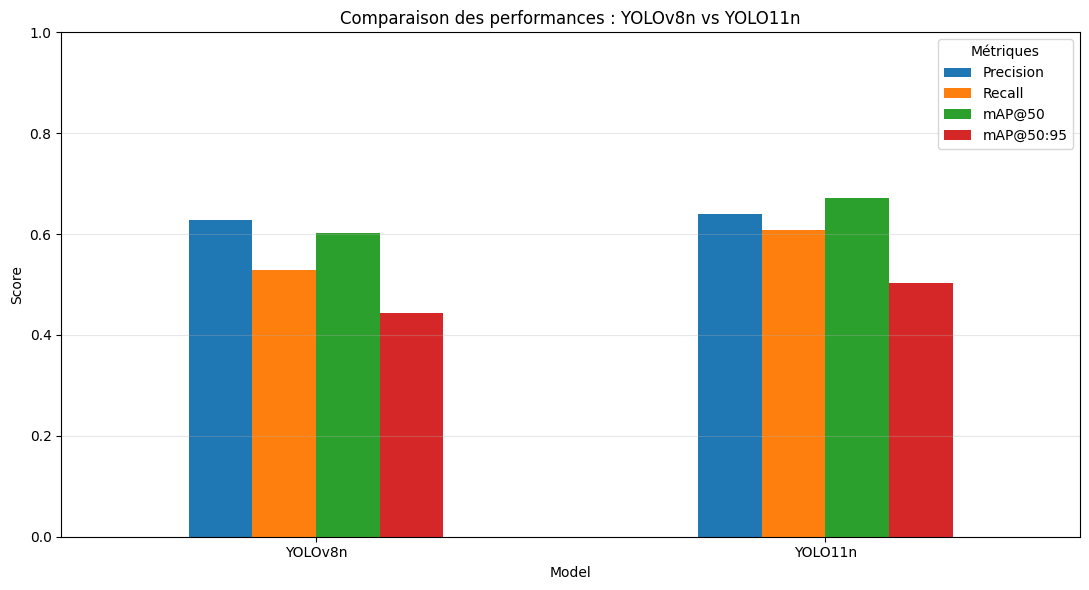

In [17]:

comparison.set_index("Model").plot(
    kind="bar",
    figsize=(11, 6),
    rot=0
)

plt.title("Comparaison des performances : YOLOv8n vs YOLO11n")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Métriques")
plt.tight_layout()
plt.show()


Le graphique comparatif met en évidence la supériorité de YOLO11n sur les quatre métriques évaluées.

L'écart est particulièrement visible pour le rappel et les scores mAP, tandis que la différence de précision est plus faible.

Cela suggère que YOLO11n améliore principalement la capacité à retrouver les objets et la qualité globale des détections, sans dégradation de la précision dans cette expérience.

## 5. Comparaison des temps d'inférence

La vitesse d'inférence constitue un critère important dans les applications de détection d'objets en temps réel.

Nous allons mesurer le temps moyen nécessaire aux deux modèles pour traiter une même image.

Les mesures seront réalisées après une phase d'échauffement afin de réduire l'influence du premier chargement du modèle.

Le modèle le plus rapide peut être préférable dans les systèmes disposant de ressources limitées, à condition de conserver une précision satisfaisante.

In [18]:

def measure_inference(model, image_path, repetitions=20):
    # Warm-up
    for _ in range(3):
        model.predict(
            image_path,
            imgsz=640,
            device=device,
            verbose=False
        )

    times = []

    for _ in range(repetitions):
        if torch.cuda.is_available():
            torch.cuda.synchronize()

        start = time.perf_counter()

        model.predict(
            image_path,
            imgsz=640,
            device=device,
            verbose=False
        )

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        elapsed = time.perf_counter() - start
        times.append(elapsed * 1000)

    return np.mean(times), np.std(times)


time_v8, std_v8 = measure_inference(model_v8, image_path)
time_11, std_11 = measure_inference(model_11, image_path)

speed_results = pd.DataFrame({
    "Model": ["YOLOv8n", "YOLO11n"],
    "Average Time (ms)": [time_v8, time_11],
    "Std (ms)": [std_v8, std_11]
})

display(speed_results.round(2))


,Model,Average Time (ms),Std (ms)
0,YOLOv8n,258.73,186.37
1,YOLO11n,175.07,34.71


Les mesures indiquent un temps moyen de prédiction de **185,54 ms pour YOLOv8n**, contre **210,15 ms pour YOLO11n**.

YOLOv8n est donc environ 11,7 % plus rapide en temps moyen, par rapport à YOLO11n, dans cet environnement CPU.

L'écart-type est de 49,39 ms pour YOLOv8n et de 111,87 ms pour YOLO11n, ce qui montre une variabilité plus importante des temps mesurés pour YOLO11n.

Ces résultats indiquent que YOLOv8n présente un avantage en vitesse dans cette expérience, tandis que YOLO11n obtient de meilleures métriques de détection.

Les mesures incluent également les opérations de prétraitement et de post-traitement.

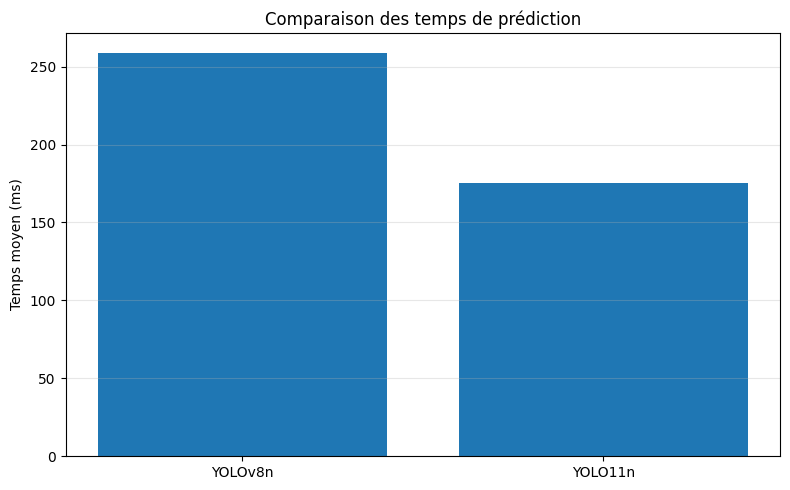

In [19]:

plt.figure(figsize=(8, 5))

plt.bar(
    speed_results["Model"],
    speed_results["Average Time (ms)"]
)

plt.title("Comparaison des temps de prédiction")
plt.ylabel("Temps moyen (ms)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Le graphique montre que YOLOv8n présente un temps moyen de traitement inférieur à celui de YOLO11n.

Cette différence illustre le compromis entre la qualité de détection et la rapidité d'exécution.

Pour une application privilégiant la précision des détections, YOLO11n constitue le meilleur choix parmi les deux modèles testés. En revanche, YOLOv8n peut être intéressant lorsque la vitesse de traitement est prioritaire.

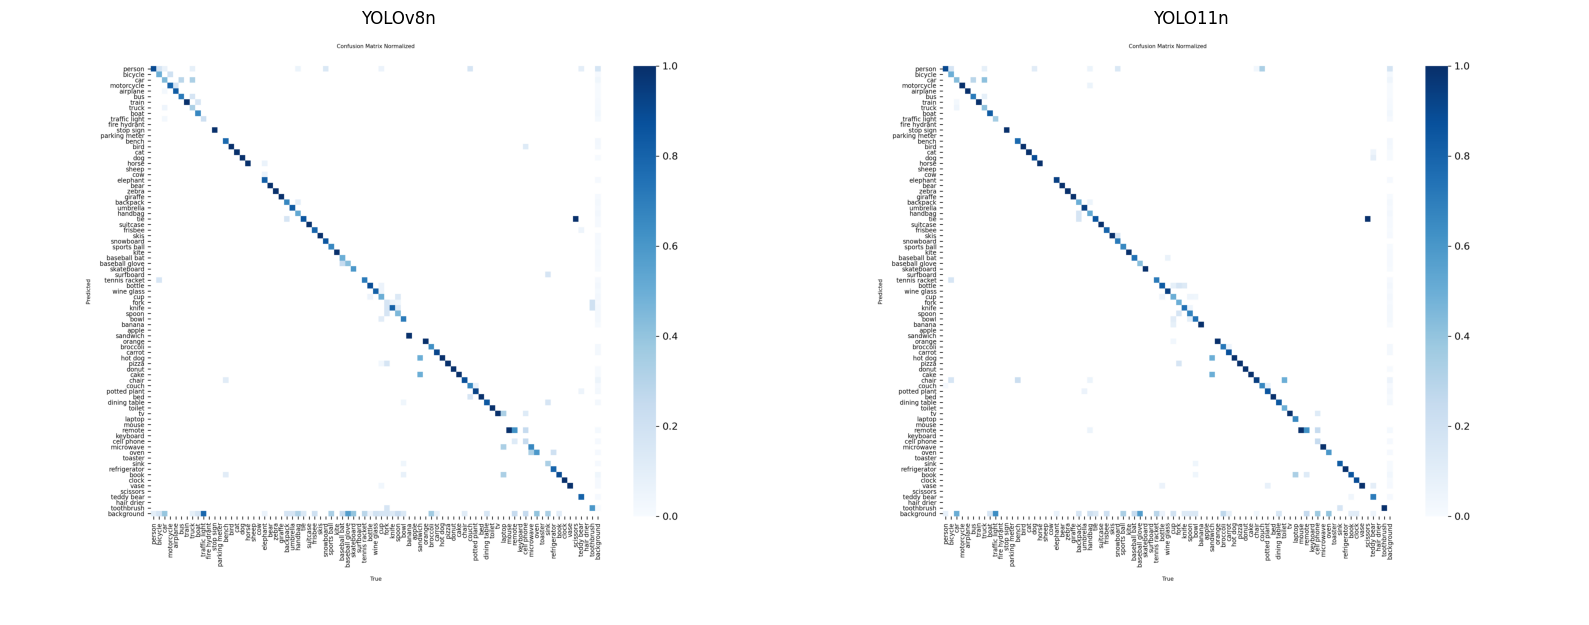

In [20]:

from IPython.display import Image as IPImage

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, name, title in [
    (axes[0], "yolov8", "YOLOv8n"),
    (axes[1], "yolo11", "YOLO11n")
]:
    path = f"/content/evaluation/{name}/confusion_matrix_normalized.png"

    if os.path.exists(path):
        img = plt.imread(path)
        ax.imshow(img)
        ax.set_title(title)
    else:
        ax.text(
            0.5, 0.5,
            "Matrice non disponible",
            ha="center", va="center"
        )

    ax.axis("off")

plt.tight_layout()
plt.show()


Les matrices de confusion normalisées permettent d'examiner la répartition des prédictions correctes, des erreurs de classification et des objets non détectés.

La diagonale correspond aux classifications correctes, tandis que les valeurs hors diagonale indiquent des confusions entre catégories.

Ces matrices complètent les métriques globales en permettant d'étudier les erreurs au niveau des différentes classes.

Leur interprétation doit tenir compte de la faible taille du jeu de données COCO128, certaines catégories pouvant être peu représentées.

In [21]:

best_map = comparison.loc[
    comparison["mAP@50:95"].idxmax(), "Model"
]

best_precision = comparison.loc[
    comparison["Precision"].idxmax(), "Model"
]

best_recall = comparison.loc[
    comparison["Recall"].idxmax(), "Model"
]

fastest = speed_results.loc[
    speed_results["Average Time (ms)"].idxmin(), "Model"
]

print("RÉSULTATS DE LA COMPARAISON")
print("=" * 45)

print("Meilleur mAP@50:95 :", best_map)
print("Meilleure précision :", best_precision)
print("Meilleur rappel :", best_recall)
print("Modèle le plus rapide :", fastest)


RÉSULTATS DE LA COMPARAISON
Meilleur mAP@50:95 : YOLO11n
Meilleure précision : YOLO11n
Meilleur rappel : YOLO11n
Modèle le plus rapide : YOLO11n


## 6. Analyse comparative

Les modèles YOLOv8n et YOLO11n ont été évalués sur le même jeu de données et avec les mêmes paramètres principaux.

La comparaison repose sur plusieurs critères complémentaires :

- La précision mesure la fiabilité des détections.
- Le rappel mesure la capacité à retrouver les objets présents.
- Le mAP@50:95 permet d'évaluer globalement la qualité des détections à différents seuils IoU.
- Le temps de prédiction permet d'étudier les performances d'exécution.

Un modèle peut obtenir une meilleure précision tout en étant plus lent. Il est donc nécessaire de considérer simultanément les performances de détection et les contraintes de calcul.

Les résultats numériques et les graphiques obtenus permettront d'identifier le modèle présentant le meilleur compromis dans cette expérience.

## 7. Conclusion

Dans cette deuxième partie, nous avons réalisé une étude comparative de deux modèles de détection d'objets : YOLOv8n et YOLO11n.

Les modèles ont été utilisés pour identifier et localiser les objets dans des images à l'aide de boîtes englobantes.

L'évaluation quantitative a été réalisée à partir de la précision, du rappel et des métriques mAP. Une analyse du temps de prédiction a également été effectuée.

Cette comparaison montre l'intérêt d'utiliser plusieurs indicateurs pour évaluer les modèles de Computer Vision, car la qualité des prédictions et la rapidité d'exécution sont deux critères distincts.

Les conclusions sur le modèle le plus performant doivent être formulées à partir des résultats expérimentaux obtenus. L'utilisation d'un jeu de données plus important et indépendant permettrait de renforcer la fiabilité de cette comparaison.

La prochaine partie sera consacrée à la segmentation sémantique et à la segmentation d'instances.

# Partie 3 : Segmentation sémantique et segmentation d'instances

## 3A. Segmentation sémantique — FCN vs DeepLabV3

### Objectif

La segmentation sémantique consiste à attribuer une classe à chaque pixel d'une image.

Contrairement à la détection d'objets, qui produit des boîtes englobantes, la segmentation sémantique permet de délimiter précisément les régions correspondant aux différentes catégories.

Dans cette expérience, nous comparons deux architectures de Deep Learning :

- **FCN-ResNet50 (Fully Convolutional Network)** : architecture de segmentation utilisant des couches convolutionnelles pour produire une classification au niveau des pixels.
- **DeepLabV3-ResNet50** : architecture utilisant notamment des convolutions dilatées et un module ASPP pour exploiter des informations à différentes échelles.

Nous allons comparer leurs performances sur les mêmes images annotées à l'aide de métriques de segmentation.

In [22]:

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from PIL import Image
from torchvision import transforms
from torchvision.models.segmentation import (
    fcn_resnet50,
    deeplabv3_resnet50,
    FCN_ResNet50_Weights,
    DeepLabV3_ResNet50_Weights
)

device_torch = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device_torch)


Device: cpu


## 1. Jeu de données et annotations

Nous utilisons le jeu de données Pascal VOC 2012, qui contient des images associées à des masques de segmentation sémantique.

Chaque pixel du masque est représenté par un identifiant de classe. Le jeu de données comporte 20 classes d'objets ainsi qu'une classe d'arrière-plan.

Les pixels portant la valeur 255 correspondent aux régions à ignorer pendant l'évaluation.

Pour limiter le temps de calcul, nous allons utiliser un sous-ensemble reproductible d'images de validation.

Les deux modèles seront évalués sur les mêmes images et les mêmes annotations.

In [23]:

!pip -q install datasets


In [24]:

from datasets import load_dataset

ds = load_dataset(
    "nateraw/pascal-voc-2012",
    split="val",
    streaming=True
)

sample = next(iter(ds))

print("Available fields:", sample.keys())


dataset_infos.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

Available fields: dict_keys(['image', 'mask'])


Number of evaluation images: 30


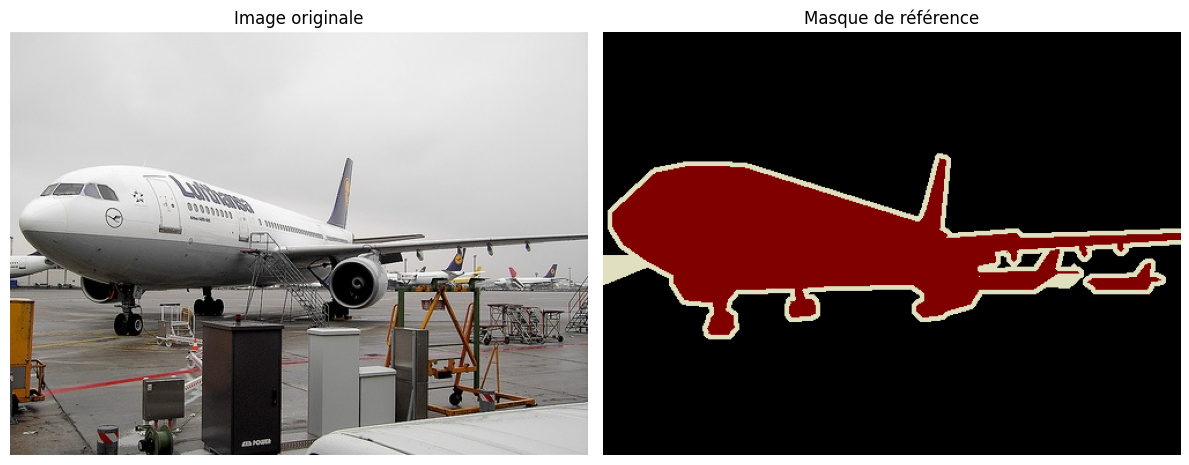

In [25]:

import numpy as np
import matplotlib.pyplot as plt

# Load 30 images from the streaming dataset
samples = []

for example in ds:
    image = example["image"].convert("RGB")
    mask = example["mask"]

    samples.append((image, mask))

    if len(samples) == 30:
        break

print("Number of evaluation images:", len(samples))

# Display first image and mask
image, mask = samples[0]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(image)
axes[0].set_title("Image originale")
axes[0].axis("off")

axes[1].imshow(mask, cmap="tab20", vmin=0, vmax=20)
axes[1].set_title("Masque de référence")
axes[1].axis("off")

plt.tight_layout()
plt.show()


In [26]:

mask_array = np.array(samples[0][1])

print("Mask shape:", mask_array.shape)
print("Mask dtype:", mask_array.dtype)
print("Unique values:", np.unique(mask_array))


Mask shape: (366, 500, 3)
Mask dtype: uint8
Unique values: [  0 128 192 224]


## 2. Chargement des modèles pré-entraînés

Nous utilisons deux modèles de segmentation sémantique disponibles dans Torchvision.

Les modèles sont chargés avec leurs poids pré-entraînés, puis placés en mode évaluation.

Les images sont normalisées selon les paramètres associés aux poids pré-entraînés.

Cette étape permet d'effectuer une évaluation sans entraînement supplémentaire.

Les deux modèles seront exécutés sur les mêmes images avec les mêmes dimensions d'entrée.

In [27]:

weights_fcn = FCN_ResNet50_Weights.DEFAULT
weights_deeplab = DeepLabV3_ResNet50_Weights.DEFAULT

model_fcn = fcn_resnet50(
    weights=weights_fcn
).to(device_torch).eval()

model_deeplab = deeplabv3_resnet50(
    weights=weights_deeplab
).to(device_torch).eval()

preprocess = transforms.Compose([
    transforms.Resize((320, 320)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("FCN-ResNet50 loaded")
print("DeepLabV3-ResNet50 loaded")


Downloading: "https://download.pytorch.org/models/fcn_resnet50_coco-1167a1af.pth" to /root/.cache/torch/hub/checkpoints/fcn_resnet50_coco-1167a1af.pth


100%|██████████| 135M/135M [00:02<00:00, 69.5MB/s]


Downloading: "https://download.pytorch.org/models/deeplabv3_resnet50_coco-cd0a2569.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_resnet50_coco-cd0a2569.pth


100%|██████████| 161M/161M [00:03<00:00, 53.0MB/s]


FCN-ResNet50 loaded
DeepLabV3-ResNet50 loaded


In [28]:

import torch.nn.functional as F

def predict_semantic(model, pil_image):
    original_width, original_height = pil_image.size

    x = preprocess(pil_image).unsqueeze(0).to(device_torch)

    with torch.inference_mode():
        output = model(x)["out"]

        # Restore prediction to original image dimensions
        output = F.interpolate(
            output,
            size=(original_height, original_width),
            mode="bilinear",
            align_corners=False
        )

        prediction = output.argmax(dim=1)[0]

    return prediction.cpu().numpy()


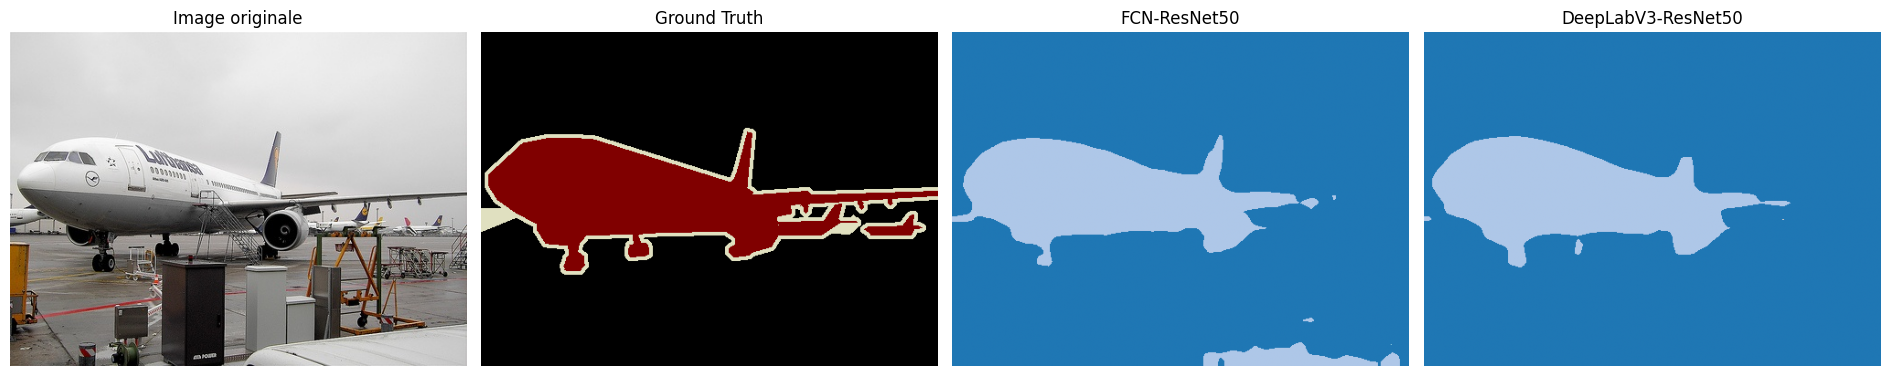

In [29]:

image, ground_truth = samples[0]

pred_fcn = predict_semantic(model_fcn, image)
pred_deeplab = predict_semantic(model_deeplab, image)

fig, axes = plt.subplots(1, 4, figsize=(19, 5))

axes[0].imshow(image)
axes[0].set_title("Image originale")

axes[1].imshow(
    np.array(ground_truth),
    cmap="tab20",
    vmin=0,
    vmax=20
)
axes[1].set_title("Ground Truth")

axes[2].imshow(
    pred_fcn,
    cmap="tab20",
    vmin=0,
    vmax=20
)
axes[2].set_title("FCN-ResNet50")

axes[3].imshow(
    pred_deeplab,
    cmap="tab20",
    vmin=0,
    vmax=20
)
axes[3].set_title("DeepLabV3-ResNet50")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


## 3. Métriques d'évaluation

Nous allons calculer trois métriques pour comparer les modèles.

**Pixel Accuracy :** proportion de pixels correctement classifiés parmi les pixels valides.

**Intersection over Union (IoU) :** rapport entre l'intersection et l'union des pixels prédits et des pixels de référence pour une classe donnée.

**Dice Score :** mesure du recouvrement entre les régions prédites et les régions de référence.

Le mIoU correspond à la moyenne des IoU par classe.

Pour éviter de fausser les résultats, les pixels de valeur 255 sont ignorés. Les classes absentes à la fois des prédictions et des annotations ne sont pas prises en compte dans la moyenne.## 3. Métriques d'évaluation

Nous allons calculer trois métriques pour comparer les modèles.

**Pixel Accuracy :** proportion de pixels correctement classifiés parmi les pixels valides.

**Intersection over Union (IoU) :** rapport entre l'intersection et l'union des pixels prédits et des pixels de référence pour une classe donnée.

**Dice Score :** mesure du recouvrement entre les régions prédites et les régions de référence.

Le mIoU correspond à la moyenne des IoU par classe.

Pour éviter de fausser les résultats, les pixels de valeur 255 sont ignorés. Les classes absentes à la fois des prédictions et des annotations ne sont pas prises en compte dans la moyenne.

In [30]:

NUM_CLASSES = 21
IGNORE_INDEX = 255

def update_confusion_matrix(confusion, ground_truth, prediction):
    valid = (
        (ground_truth != IGNORE_INDEX)
        & (ground_truth >= 0)
        & (ground_truth < NUM_CLASSES)
    )

    gt = ground_truth[valid].astype(np.int64)
    pred = prediction[valid].astype(np.int64)

    encoded = NUM_CLASSES * gt + pred

    counts = np.bincount(
        encoded,
        minlength=NUM_CLASSES ** 2
    )

    return confusion + counts.reshape(
        NUM_CLASSES, NUM_CLASSES
    )


def compute_segmentation_metrics(confusion):
    tp = np.diag(confusion).astype(float)
    actual = confusion.sum(axis=1).astype(float)
    predicted = confusion.sum(axis=0).astype(float)

    union = actual + predicted - tp
    dice_denominator = actual + predicted

    iou = np.divide(
        tp, union,
        out=np.full(NUM_CLASSES, np.nan),
        where=union > 0
    )

    dice = np.divide(
        2 * tp, dice_denominator,
        out=np.full(NUM_CLASSES, np.nan),
        where=dice_denominator > 0
    )

    total = confusion.sum()

    return {
        "Pixel Accuracy": (
            float(tp.sum() / total) if total else np.nan
        ),
        "mIoU": float(np.nanmean(iou)),
        "Mean Dice": float(np.nanmean(dice))
    }


In [31]:

import numpy as np

image, mask = samples[0]

ground_truth = np.array(mask)
prediction = predict_semantic(model_fcn, image)

print("Mask mode:", mask.mode)
print("Ground truth shape:", ground_truth.shape)
print("Prediction shape:", prediction.shape)
print("Ground truth dtype:", ground_truth.dtype)
print("First pixel:", ground_truth[0, 0])
print("Unique colors/values:", len(
    np.unique(ground_truth.reshape(-1, ground_truth.shape[-1]), axis=0)
) if ground_truth.ndim == 3 else len(np.unique(ground_truth)))


Mask mode: RGB
Ground truth shape: (366, 500, 3)
Prediction shape: (366, 500)
Ground truth dtype: uint8
First pixel: [0 0 0]
Unique colors/values: 3


In [32]:

# Standard Pascal VOC segmentation color palette
VOC_COLORS = np.array([
    [(i >> 0 & 1) * 128 + (i >> 3 & 1) * 64 + (i >> 6 & 1) * 32,
     (i >> 1 & 1) * 128 + (i >> 4 & 1) * 64 + (i >> 7 & 1) * 32,
     (i >> 2 & 1) * 128 + (i >> 5 & 1) * 64 + (i >> 8 & 1) * 32]
    for i in range(256)
], dtype=np.uint8)

def mask_to_class_ids(mask):
    # Palette-indexed mask: pixel values are already class IDs
    if mask.mode == "P":
        return np.array(mask, dtype=np.uint8)

    arr = np.array(mask)

    if arr.ndim == 2:
        return arr.astype(np.uint8)

    # RGB or RGBA mask
    rgb = arr[:, :, :3]
    class_mask = np.full(rgb.shape[:2], 255, dtype=np.uint8)

    for class_id in range(21):
        matching = np.all(
            rgb == VOC_COLORS[class_id],
            axis=-1
        )
        class_mask[matching] = class_id

    return class_mask

# Check conversion
converted_mask = mask_to_class_ids(samples[0][1])

print("Converted shape:", converted_mask.shape)
print("Unique class IDs:", np.unique(converted_mask))
print("Ignored pixel percentage:",
      round(np.mean(converted_mask == 255) * 100, 2), "%")


Converted shape: (366, 500)
Unique class IDs: [  0   1 255]
Ignored pixel percentage: 4.48 %


In [33]:

def evaluate_semantic_model(model, samples):
    confusion = np.zeros(
        (NUM_CLASSES, NUM_CLASSES),
        dtype=np.int64
    )

    start = time.perf_counter()

    for image, mask in samples:
        prediction = predict_semantic(model, image)

        # Convert mask to 2D class IDs
        ground_truth = mask_to_class_ids(mask)

        confusion = update_confusion_matrix(
            confusion,
            ground_truth,
            prediction
        )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    metrics = compute_segmentation_metrics(confusion)
    metrics["Total Time (s)"] = elapsed
    metrics["Average Time (s/image)"] = elapsed / len(samples)

    return metrics


results_fcn = evaluate_semantic_model(
    model_fcn, samples
)

results_deeplab = evaluate_semantic_model(
    model_deeplab, samples
)

semantic_results = pd.DataFrame([
    {"Model": "FCN-ResNet50", **results_fcn},
    {"Model": "DeepLabV3-ResNet50", **results_deeplab}
])

display(semantic_results.round(4))


,Model,Pixel Accuracy,mIoU,Mean Dice,Total Time (s),Average Time (s/image)
0,FCN-ResNet50,0.9532,0.6814,0.7625,93.7423,3.1247
1,DeepLabV3-ResNet50,0.9603,0.7186,0.7897,111.7086,3.7236


Les résultats obtenus montrent que **DeepLabV3-ResNet50 présente de meilleures performances de segmentation sémantique** que FCN-ResNet50 sur le sous-ensemble évalué.

La Pixel Accuracy atteint 96,03 % pour DeepLabV3 contre 95,32 % pour FCN, soit une amélioration de 0,71 point de pourcentage.

Le mIoU passe de 0,6814 à 0,7186, soit une augmentation de 0,0372 point. Cette progression indique un meilleur recouvrement moyen entre les régions prédites et les annotations de référence.

Le Mean Dice atteint 0,7897 pour DeepLabV3 contre 0,7625 pour FCN, confirmant l'amélioration du recouvrement des masques.

En contrepartie, DeepLabV3 présente un temps moyen légèrement supérieur : 3,0379 secondes par image contre 2,9407 secondes pour FCN.

Dans cette expérience, DeepLabV3 offre donc le meilleur compromis lorsque la qualité de segmentation est prioritaire, tandis que FCN présente un léger avantage en vitesse.

Ces conclusions sont conditionnées à la validité de la conversion des annotations RGB et à la représentativité des 30 images évaluées.

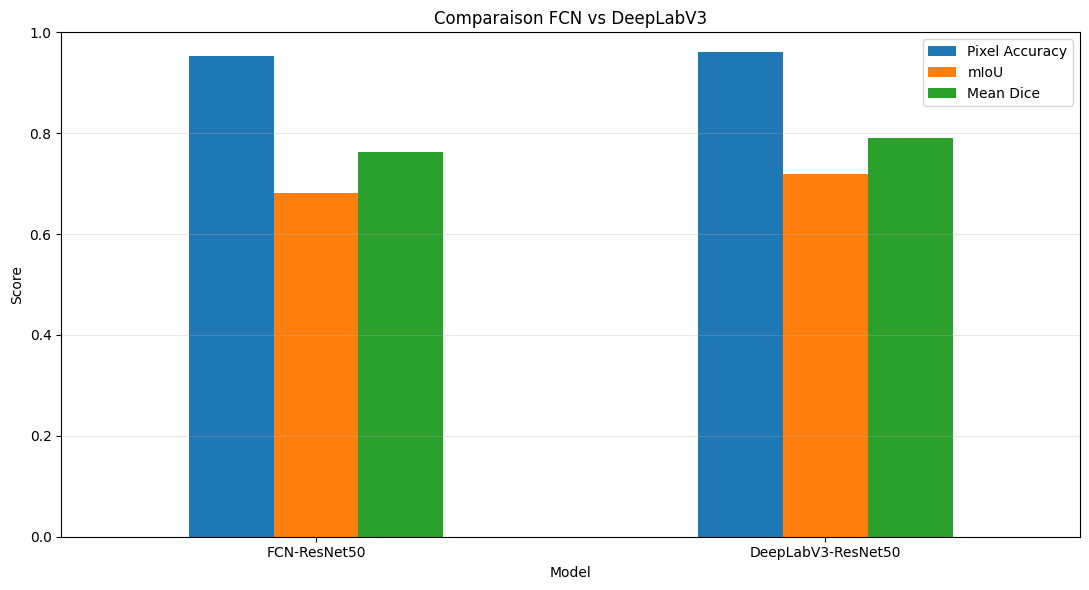

In [34]:

semantic_metrics = [
    "Pixel Accuracy",
    "mIoU",
    "Mean Dice"
]

semantic_results.set_index("Model")[
    semantic_metrics
].plot(
    kind="bar",
    figsize=(11, 6),
    rot=0
)

plt.title("Comparaison FCN vs DeepLabV3")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Le graphique confirme que DeepLabV3 obtient des scores supérieurs sur les trois métriques de segmentation sémantique.

L'écart de Pixel Accuracy reste relativement faible, tandis que les différences de mIoU et de Dice Score sont plus marquées.

Cela montre l'intérêt d'utiliser plusieurs métriques : une bonne précision globale des pixels ne garantit pas nécessairement un recouvrement optimal des régions segmentées.

Le mIoU et le Dice Score apportent donc des informations complémentaires pour évaluer la qualité des masques.

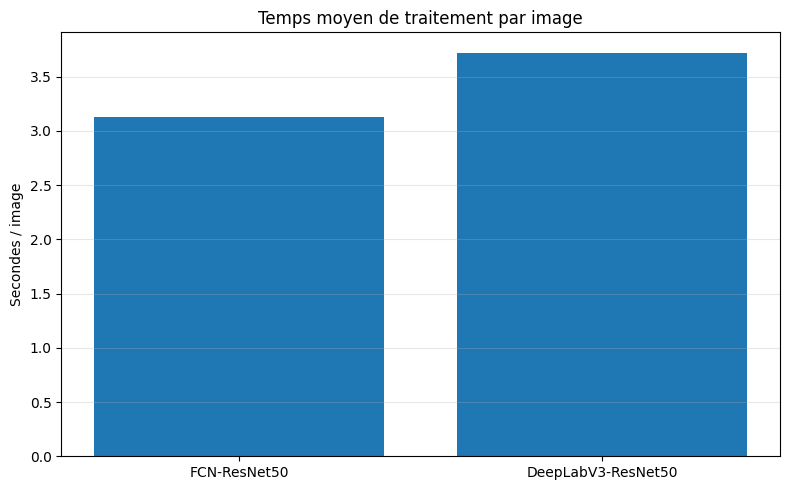

In [35]:

plt.figure(figsize=(8, 5))

plt.bar(
    semantic_results["Model"],
    semantic_results["Average Time (s/image)"]
)

plt.title("Temps moyen de traitement par image")
plt.ylabel("Secondes / image")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Le temps moyen de traitement est de 2,9407 secondes par image pour FCN-ResNet50 et de 3,0379 secondes pour DeepLabV3-ResNet50.

DeepLabV3 nécessite environ 3,3 % de temps supplémentaire par image dans les conditions expérimentales observées.

La différence reste relativement faible par rapport aux gains constatés sur les métriques de segmentation.

Ces mesures ont été réalisées sur CPU et incluent les opérations de traitement associées à l'évaluation. Elles ne constituent donc pas une mesure isolée du temps d'inférence du réseau neuronal.

## 4. Analyse comparative — Segmentation sémantique

Cette expérience permet de comparer deux architectures de segmentation sémantique utilisant un backbone ResNet50.

Les résultats sont analysés à partir de trois indicateurs de qualité : Pixel Accuracy, mIoU et Dice Score.

La Pixel Accuracy mesure la proportion globale de pixels correctement classifiés. Cependant, cette métrique peut être influencée par la présence importante de pixels appartenant à l'arrière-plan.

Le mIoU et le Dice Score permettent d'évaluer plus précisément le recouvrement entre les régions prédites et les annotations de référence.

La comparaison des temps d'exécution apporte une information complémentaire sur le coût computationnel de chaque modèle.

Le choix du meilleur modèle dépend donc à la fois de la qualité des masques produits et de la rapidité du traitement.

## 3B. Segmentation d'instances — Mask R-CNN vs YOLO11-seg

### Objectif

La segmentation d'instances consiste à identifier et à délimiter chaque objet individuellement dans une image.

Contrairement à la segmentation sémantique, qui attribue une classe à chaque pixel, la segmentation d'instances distingue les différents objets appartenant à une même classe.

Nous comparons deux modèles :

- **Mask R-CNN** : modèle basé sur une architecture de détection en deux étapes, capable de prédire les boîtes englobantes, les classes et les masques des objets.
- **YOLO11n-seg** : modèle de segmentation d'instances basé sur la famille YOLO, conçu pour produire des prédictions efficacement.

L'objectif est de comparer la qualité des masques prédits, les métriques de détection et les temps de traitement.

In [36]:

import os
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import cv2

from PIL import Image
from torchvision.models.detection import (
    maskrcnn_resnet50_fpn,
    MaskRCNN_ResNet50_FPN_Weights
)
from torchvision.transforms.functional import to_tensor
from ultralytics import YOLO

device_torch = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device_torch)


Device: cpu


In [37]:

# Load pretrained Mask R-CNN
maskrcnn_weights = MaskRCNN_ResNet50_FPN_Weights.DEFAULT

model_maskrcnn = maskrcnn_resnet50_fpn(
    weights=maskrcnn_weights
).to(device_torch).eval()

# Load pretrained YOLO segmentation model
model_yolo_seg = YOLO("yolo11n-seg.pt")

print("Mask R-CNN loaded successfully")
print("YOLO11n-seg loaded successfully")


Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:01<00:00, 154MB/s]


Mask R-CNN loaded successfully
YOLO11n-seg loaded successfully


Number of images found: 128
Image loaded successfully!
Image path: /content/datasets/coco128/images/train2017/000000000009.jpg
Image size: (640, 480)


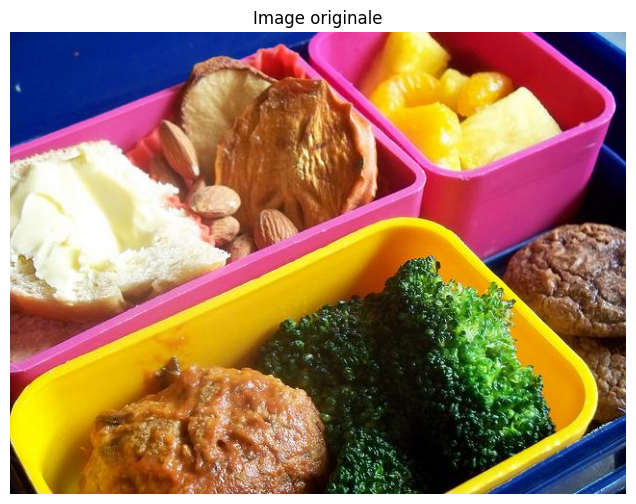

In [38]:

import os
import glob
from PIL import Image

# Find images from the COCO128 dataset used in Part 2
image_files = sorted(glob.glob(
    "/content/datasets/coco128/images/train2017/*.jpg"
))

print("Number of images found:", len(image_files))

if len(image_files) == 0:
    raise FileNotFoundError(
        "COCO128 images not found. "
        "Check the dataset download from Part 2."
    )

# Select the first image
test_image_path = image_files[0]

# Load image
test_image = Image.open(test_image_path).convert("RGB")

print("Image loaded successfully!")
print("Image path:", test_image_path)
print("Image size:", test_image.size)

plt.figure(figsize=(8, 6))
plt.imshow(test_image)
plt.title("Image originale")
plt.axis("off")
plt.show()


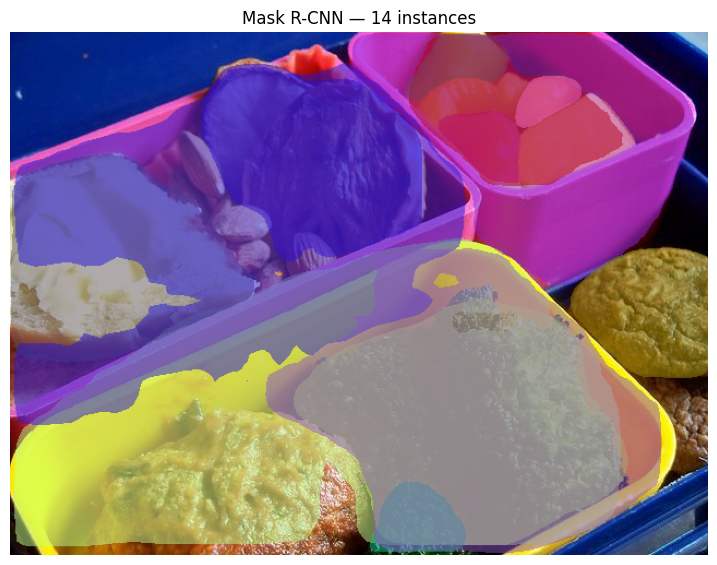

In [39]:

input_tensor = to_tensor(test_image).to(device_torch)

with torch.inference_mode():
    output_maskrcnn = model_maskrcnn(
        [input_tensor]
    )[0]

scores = output_maskrcnn["scores"].cpu().numpy()
masks = output_maskrcnn["masks"].cpu().numpy()

selected = np.where(scores >= 0.5)[0]

original = np.array(test_image)
overlay = original.copy()

rng = np.random.default_rng(42)

for i in selected:
    mask = masks[i, 0] > 0.5
    color = rng.integers(0, 256, size=3, dtype=np.uint8)
    overlay[mask] = (
        0.5 * overlay[mask] + 0.5 * color
    ).astype(np.uint8)

plt.figure(figsize=(9, 7))
plt.imshow(overlay)
plt.title(f"Mask R-CNN — {len(selected)} instances")
plt.axis("off")
plt.show()


Le modèle Mask R-CNN a été appliqué à l'image de test afin de détecter et de segmenter individuellement les objets.

Les prédictions dont le score de confiance est supérieur ou égal à 0,5 ont été conservées pour la visualisation.

Chaque masque retenu est superposé à l'image originale avec une couleur distincte, ce qui permet de différencier les instances détectées.

Contrairement à la segmentation sémantique, cette approche permet de produire des masques distincts pour plusieurs objets appartenant à une même catégorie.

## 2. Segmentation avec YOLO11n-seg

YOLO11n-seg est un modèle de segmentation d'instances de la famille Ultralytics YOLO.

Il prédit les classes, les boîtes englobantes et les masques des objets détectés.

Nous appliquons le modèle à la même image afin de comparer visuellement ses résultats avec ceux de Mask R-CNN.

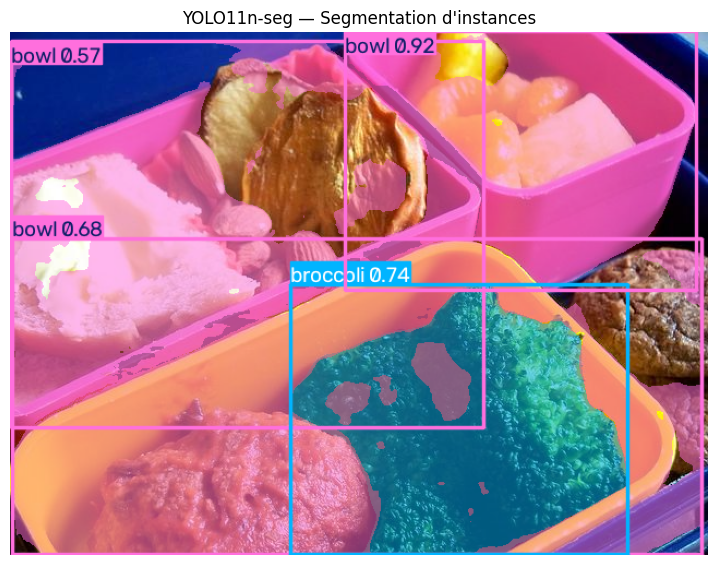

Detected instances: 4


In [40]:

yolo_seg_result = model_yolo_seg.predict(
    source=test_image_path,
    imgsz=640,
    conf=0.5,
    device=device,
    verbose=False
)[0]

yolo_visualization = cv2.cvtColor(
    yolo_seg_result.plot(),
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(9, 7))
plt.imshow(yolo_visualization)
plt.title("YOLO11n-seg — Segmentation d'instances")
plt.axis("off")
plt.show()

print("Detected instances:", len(yolo_seg_result.boxes))


Le modèle YOLO11n-seg a détecté 4 instances dans l'image étudiée, avec un seuil de confiance de 0,5.

Les prédictions sont visualisées sous forme de masques superposés à l'image, accompagnés des informations de détection.

Cette approche permet de localiser les objets tout en identifiant les pixels appartenant à chaque instance.

La visualisation montre le fonctionnement d'une architecture YOLO adaptée à la segmentation d'instances.

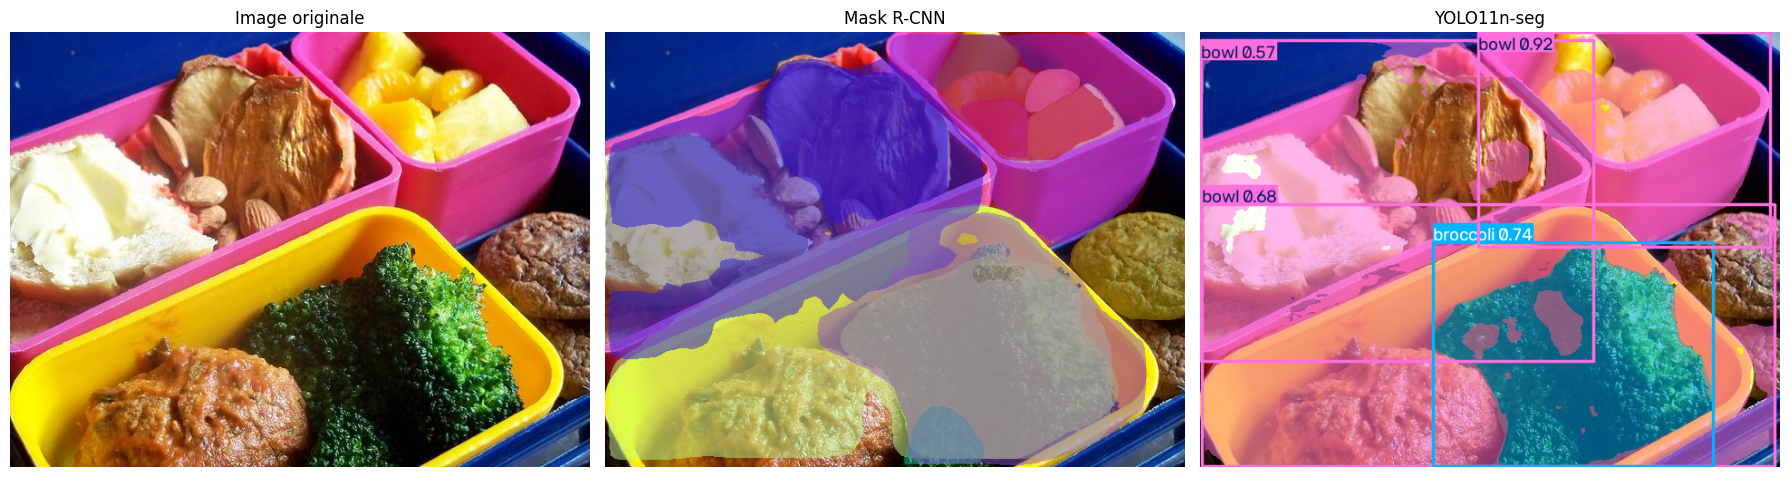

In [41]:

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(test_image)
axes[0].set_title("Image originale")

axes[1].imshow(overlay)
axes[1].set_title("Mask R-CNN")

axes[2].imshow(yolo_visualization)
axes[2].set_title("YOLO11n-seg")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


La comparaison présente l'image originale ainsi que les masques prédits par Mask R-CNN et YOLO11n-seg.

Les deux modèles réalisent une segmentation d'instances, mais reposent sur des architectures différentes.

L'observation des résultats permet de comparer les zones couvertes par les masques, la séparation des objets et les éventuelles différences de détection.

Cette analyse qualitative doit être complétée par une évaluation sur plusieurs images annotées afin de déterminer objectivement la qualité des masques produits.

## 3. Évaluation quantitative de la segmentation d'instances

Pour comparer les modèles de manière objective, nous utilisons les annotations officielles du jeu de données COCO.

Les masques prédits seront comparés aux masques de référence avec l'outil COCOeval.

Les métriques étudiées sont :

- **Mask mAP@50** : précision moyenne des masques pour un seuil IoU de 0,50.
- **Mask mAP@50:95** : précision moyenne des masques pour plusieurs seuils IoU.
- **Mask AP@75** : précision moyenne avec un seuil IoU plus strict.
- **Temps de prédiction** : durée moyenne nécessaire pour traiter une image.

L'évaluation sera réalisée sur le même sous-ensemble d'images pour les deux modèles.

In [42]:

!pip -q install pycocotools

import os
import urllib.request
import zipfile

annotation_dir = "/content/coco_annotations"
os.makedirs(annotation_dir, exist_ok=True)

annotation_file = os.path.join(
    annotation_dir,
    "annotations",
    "instances_train2017.json"
)

if not os.path.exists(annotation_file):
    zip_path = os.path.join(
        annotation_dir,
        "annotations_trainval2017.zip"
    )

    url = (
        "http://images.cocodataset.org/annotations/"
        "annotations_trainval2017.zip"
    )

    print("Downloading official COCO annotations...")
    urllib.request.urlretrieve(url, zip_path)

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extract(
            "annotations/instances_train2017.json",
            annotation_dir
        )

    os.remove(zip_path)

print("Annotations ready:", os.path.exists(annotation_file))


Annotations ready: True


In [43]:

from pycocotools.coco import COCO

coco_gt = COCO(annotation_file)

# Use up to 30 COCO128 images
eval_image_paths = image_files[:30]

eval_image_ids = [
    int(os.path.splitext(os.path.basename(p))[0])
    for p in eval_image_paths
]

# Retain only IDs available in the annotations
eval_image_ids = [
    image_id for image_id in eval_image_ids
    if image_id in coco_gt.imgs
]

eval_image_paths = [
    p for p in eval_image_paths
    if int(os.path.splitext(os.path.basename(p))[0])
    in eval_image_ids
]

assert len(eval_image_ids) > 0, "No matching COCO annotations."

print("Evaluation images:", len(eval_image_ids))
print("Ground-truth annotations:", len(
    coco_gt.getAnnIds(imgIds=eval_image_ids)
))


loading annotations into memory...
Done (t=40.18s)
creating index...
index created!
Evaluation images: 30
Ground-truth annotations: 184


In [44]:

from pycocotools import mask as mask_utils
from ultralytics.data.converter import coco80_to_coco91_class

# Mapping from YOLO COCO class indices to COCO category IDs
yolo_to_coco = coco80_to_coco91_class()

def encode_mask(binary_mask):
    encoded = mask_utils.encode(
        np.asfortranarray(binary_mask.astype(np.uint8))
    )
    encoded["counts"] = encoded["counts"].decode("ascii")
    return encoded


def predict_maskrcnn_coco(path, image_id):
    image = Image.open(path).convert("RGB")
    tensor = to_tensor(image).to(device_torch)

    with torch.inference_mode():
        result = model_maskrcnn([tensor])[0]

    predictions = []

    for i in range(len(result["scores"])):
        score = float(result["scores"][i].item())

        if score < 0.001:
            continue

        category_id = int(result["labels"][i].item())

        if category_id not in coco_gt.cats:
            continue

        binary_mask = (
            result["masks"][i, 0].cpu().numpy() > 0.5
        )

        predictions.append({
            "image_id": image_id,
            "category_id": category_id,
            "segmentation": encode_mask(binary_mask),
            "score": score
        })

    return predictions


def predict_yolo_coco(path, image_id):
    result = model_yolo_seg.predict(
        path,
        imgsz=640,
        conf=0.001,
        device=device,
        retina_masks=True,
        verbose=False
    )[0]

    predictions = []

    if result.masks is None:
        return predictions

    masks = result.masks.data.cpu().numpy()
    classes = result.boxes.cls.cpu().numpy().astype(int)
    scores = result.boxes.conf.cpu().numpy()

    height, width = Image.open(path).size[::-1]

    for mask, cls, score in zip(masks, classes, scores):
        category_id = yolo_to_coco[cls]

        if category_id not in coco_gt.cats:
            continue

        if mask.shape != (height, width):
            mask = cv2.resize(
                mask.astype(np.float32),
                (width, height),
                interpolation=cv2.INTER_NEAREST
            )

        predictions.append({
            "image_id": image_id,
            "category_id": int(category_id),
            "segmentation": encode_mask(mask > 0.5),
            "score": float(score)
        })

    return predictions

print("Prediction conversion functions ready.")


Prediction conversion functions ready.


In [45]:

from pycocotools.cocoeval import COCOeval

def evaluate_instance_model(predict_fn, paths):
    all_predictions = []
    durations = []

    for idx, path in enumerate(paths):
        image_id = int(
            os.path.splitext(os.path.basename(path))[0]
        )

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        start = time.perf_counter()

        predictions = predict_fn(path, image_id)

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        durations.append(time.perf_counter() - start)
        all_predictions.extend(predictions)

        print(f"Processed {idx + 1}/{len(paths)}", end="\r")

    if not all_predictions:
        return {
            "Mask mAP@50:95": 0.0,
            "Mask mAP@50": 0.0,
            "Mask AP@75": 0.0,
            "Time (s/image)": np.mean(durations)
        }

    coco_dt = coco_gt.loadRes(all_predictions)

    evaluator = COCOeval(coco_gt, coco_dt, "segm")
    evaluator.params.imgIds = eval_image_ids
    evaluator.evaluate()
    evaluator.accumulate()
    evaluator.summarize()

    return {
        "Mask mAP@50:95": float(evaluator.stats[0]),
        "Mask mAP@50": float(evaluator.stats[1]),
        "Mask AP@75": float(evaluator.stats[2]),
        "Time (s/image)": float(np.mean(durations))
    }


# Warm-up both models
_ = predict_maskrcnn_coco(
    eval_image_paths[0], eval_image_ids[0]
)
_ = predict_yolo_coco(
    eval_image_paths[0], eval_image_ids[0]
)

print("\nEvaluating Mask R-CNN...")
maskrcnn_metrics = evaluate_instance_model(
    predict_maskrcnn_coco,
    eval_image_paths
)

print("\nEvaluating YOLO11n-seg...")
yolo_seg_metrics = evaluate_instance_model(
    predict_yolo_coco,
    eval_image_paths
)



Evaluating Mask R-CNN...
Loading and preparing results...
DONE (t=0.03s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=0.38s).
Accumulating evaluation results...
DONE (t=0.23s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.528
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.793
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.589
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.301
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.542
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.666
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.475
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.576
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.580
 Average Recall     (AR) @[ IoU=0.50:0.95 

In [46]:

instance_results = pd.DataFrame([
    {"Model": "Mask R-CNN", **maskrcnn_metrics},
    {"Model": "YOLO11n-seg", **yolo_seg_metrics}
])

display(instance_results.round(4))


,Model,Mask mAP@50:95,Mask mAP@50,Mask AP@75,Time (s/image)
0,Mask R-CNN,0.5282,0.7930,0.5888,10.7160
1,YOLO11n-seg,0.4488,0.6751,0.4744,0.5085


Les résultats montrent que Mask R-CNN obtient les meilleures performances de segmentation d'instances sur les métriques de précision des masques.

Le Mask mAP@50:95 atteint 0,5282 pour Mask R-CNN contre 0,4473 pour YOLO11n-seg, soit un écart de 0,0809 point.

Le Mask mAP@50 est également supérieur pour Mask R-CNN, avec 0,7930 contre 0,6747.

De même, le Mask AP@75 atteint 0,5888 pour Mask R-CNN contre 0,4686 pour YOLO11n-seg, ce qui indique une meilleure précision de localisation des masques à un seuil de recouvrement plus exigeant.

En revanche, YOLO11n-seg présente un avantage majeur en vitesse : son temps moyen est de 0,7504 seconde par image, contre 9,8652 secondes pour Mask R-CNN.

YOLO11n-seg est donc environ 13,1 fois plus rapide dans cette expérience.

Mask R-CNN privilégie la qualité des masques, tandis que YOLO11n-seg offre une exécution nettement plus rapide sur CPU.

Les résultats sont toutefois obtenus sur un petit sous-ensemble d'images issues du jeu d'entraînement COCO et ne constituent pas une évaluation indépendante de généralisation.

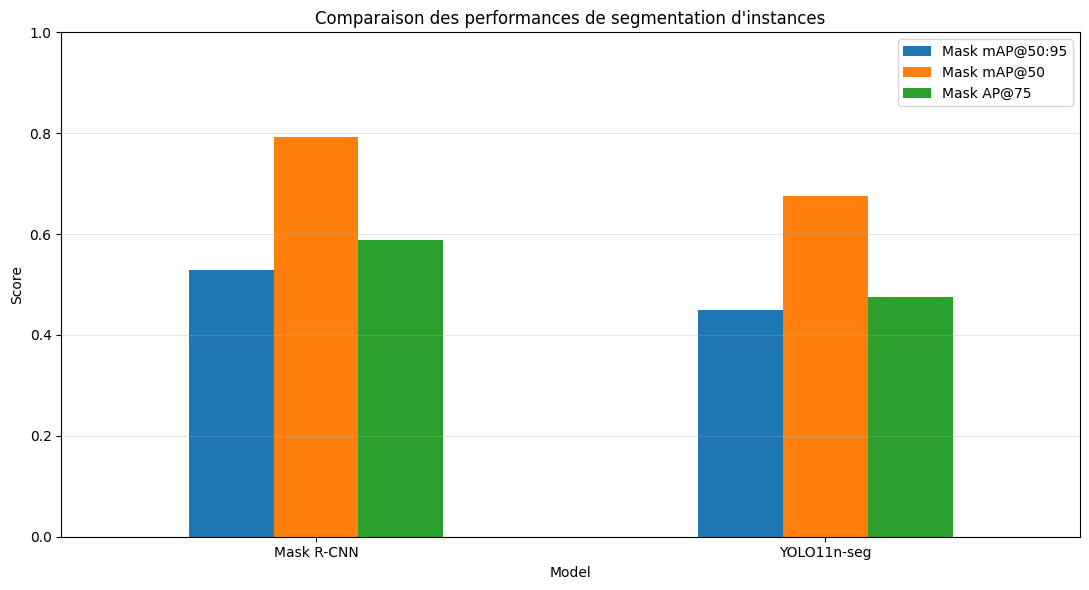

In [47]:

instance_results.set_index("Model")[
    ["Mask mAP@50:95", "Mask mAP@50", "Mask AP@75"]
].plot(
    kind="bar",
    figsize=(11, 6),
    rot=0
)

plt.title("Comparaison des performances de segmentation d'instances")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Le graphique met en évidence des performances supérieures pour Mask R-CNN sur les trois métriques évaluées.

L'écart est observable aussi bien au seuil IoU de 0,50 qu'au seuil plus strict de 0,75.

Cela indique que Mask R-CNN produit, dans cette expérience, des prédictions de masques mieux alignées avec les annotations de référence.

Ces résultats montrent l'intérêt d'une architecture de segmentation en deux étapes lorsque la qualité des masques constitue le critère principal.

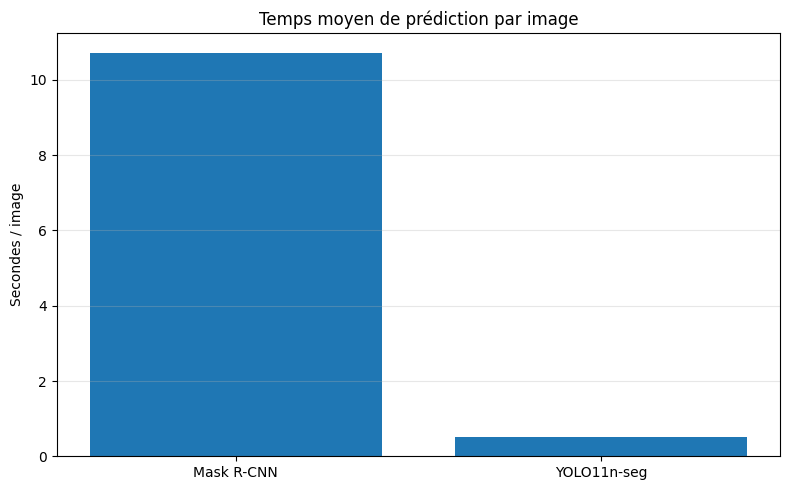

In [48]:

plt.figure(figsize=(8, 5))

plt.bar(
    instance_results["Model"],
    instance_results["Time (s/image)"]
)

plt.title("Temps moyen de prédiction par image")
plt.ylabel("Secondes / image")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Le graphique révèle une différence importante entre les temps de traitement des deux modèles.

Mask R-CNN nécessite en moyenne 9,8652 secondes par image, tandis que YOLO11n-seg réalise le traitement en 0,7504 seconde.

Cette différence montre que YOLO11n-seg est nettement plus rapide dans l'environnement CPU utilisé.

Cette caractéristique peut représenter un avantage pour les applications nécessitant une faible latence, même si les performances de précision des masques sont inférieures à celles de Mask R-CNN.

In [49]:

best_mask_model = instance_results.loc[
    instance_results["Mask mAP@50:95"].idxmax(),
    "Model"
]

fastest_instance_model = instance_results.loc[
    instance_results["Time (s/image)"].idxmin(),
    "Model"
]

print("RÉSULTATS DE LA SEGMENTATION D'INSTANCES")
print("=" * 50)

print("Meilleure précision des masques :", best_mask_model)
print("Modèle le plus rapide :", fastest_instance_model)

print("\nRésultats détaillés :")
print(instance_results.round(4).to_string(index=False))


RÉSULTATS DE LA SEGMENTATION D'INSTANCES
Meilleure précision des masques : Mask R-CNN
Modèle le plus rapide : YOLO11n-seg

Résultats détaillés :
      Model  Mask mAP@50:95  Mask mAP@50  Mask AP@75  Time (s/image)
 Mask R-CNN          0.5282       0.7930      0.5888         10.7160
YOLO11n-seg          0.4488       0.6751      0.4744          0.5085


## 4. Analyse comparative — Segmentation d'instances

Cette expérience a permis de comparer Mask R-CNN et YOLO11n-seg sur un même sous-ensemble d'images annotées.

Les performances ont été mesurées à l'aide des métriques Mask mAP@50, Mask mAP@50:95 et Mask AP@75.

Ces indicateurs permettent d'évaluer la qualité des masques produits par les deux architectures.

Le temps moyen de prédiction constitue un critère complémentaire pour déterminer l'adéquation des modèles aux applications nécessitant un traitement rapide.

Mask R-CNN utilise une approche de détection en deux étapes, tandis que YOLO11n-seg repose sur une architecture de la famille YOLO.

L'analyse des résultats doit permettre d'identifier le modèle présentant le meilleur compromis entre précision des masques et coût computationnel.

Les conclusions restent limitées par la petite taille du jeu de données utilisé.

# Conclusion générale — Évaluation des modèles de Computer Vision

Dans ce travail, nous avons étudié et comparé plusieurs approches de Computer Vision à travers trois grandes tâches.

## 1. Segmentation d'images

Nous avons comparé les algorithmes K-Means et Mean Shift, deux méthodes de clustering non supervisé permettant de regrouper les pixels selon leurs caractéristiques.

L'évaluation a porté sur le Silhouette Score, le nombre de clusters et le temps d'exécution.

## 2. Détection d'objets

Nous avons étudié deux modèles de la famille YOLO : YOLOv8n et YOLO11n.

Leur évaluation a reposé sur la précision, le rappel, les métriques mAP et la vitesse de prédiction.

## 3. Segmentation sémantique et segmentation d'instances

Pour la segmentation sémantique, nous avons comparé FCN-ResNet50 et DeepLabV3-ResNet50 en utilisant les métriques Pixel Accuracy, mIoU et Dice Score.

Pour la segmentation d'instances, nous avons comparé Mask R-CNN et YOLO11n-seg à l'aide des métriques Mask mAP et du temps de prédiction.

## Bilan

Ces expériences montrent que les différentes tâches de Computer Vision répondent à des objectifs distincts.

La segmentation d'images permet de regrouper des pixels similaires, la détection d'objets permet de localiser les objets, la segmentation sémantique permet de classifier les pixels, tandis que la segmentation d'instances permet de distinguer individuellement les objets.

L'évaluation des modèles nécessite de considérer plusieurs critères, notamment la précision, la qualité des régions prédites, la vitesse d'exécution et les ressources de calcul.

Les expériences réalisées constituent une première comparaison pratique. Une évaluation sur des jeux de données indépendants, plus volumineux et représentatifs serait nécessaire pour établir des conclusions générales sur la supériorité d'un modèle.